# Pilot preview: the synthetic images on disk

Where everything is, with the paths written out:

```
real images        /root/data/fitzpatrick17k/finalfitz17k/<md5hash>.jpg
pilot folder       /workspace/synderm/pilot/<model>-<quality>-varied-seed20261028-n16/
  reals.csv          the 16 real references per class (md5hash, label, in_n1 / in_n8 / in_n16)
  synthetic.csv      one row per (real md5hash, slot 0..9) -> location of the synthetic png
  <label-with-dashes>/edit/<slot 00..10>/<md5hash of the real reference>.png   the image itself
  <label-with-dashes>/edit/<slot>/<md5hash>.json                              status, prompt, cost
```

Slot k was generated with prompt variation k (ten body-site / framing / lighting prompts, same list for
every class). A reference whose slot was refused twice has that slot filled by an extra edit (slot 10, 11, ...)
of another accepted reference in the same class; `synthetic.csv` records that as `topup=True` with the
`source_md5` of the reference actually edited. The classifier reads `synthetic.csv`, not the folders.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

REAL_DIR = "/root/data/fitzpatrick17k/finalfitz17k"
PILOTS = {
    "gpt-image-2.5-sunburst": "/workspace/synderm/pilot/gpt-image-2.5-sunburst-medium-varied-seed20261028-n16",
    "nano-banana-2.1":        "/workspace/synderm/pilot/nano-banana-2.1-1K-varied-seed20261028-n16",
}
N_REFS = 2        # references per class to show
THUMB = 192       # px, keeps the notebook small

## Path of one synthetic image

The path follows the folder pattern above; `synthetic.csv` stores the same path in its `location` column.

In [2]:
syn = pd.read_csv(PILOTS["gpt-image-2.5-sunburst"] + "/synthetic.csv")
row = syn.iloc[0]
real_path = f"{REAL_DIR}/{row.md5hash}.jpg"
synthetic_path = f'{PILOTS["gpt-image-2.5-sunburst"]}/{row.label.replace(" ", "-")}/edit/{row.slot:02d}/{row.source_md5}.png'
print("real reference:", real_path)
print("synthetic     :", synthetic_path)
assert synthetic_path == row.location
syn.head(12)

real reference: /root/data/fitzpatrick17k/finalfitz17k/101f6f6a20207e61299a9de4902ca2ee.jpg
synthetic     : /workspace/synderm/pilot/gpt-image-2.5-sunburst-medium-varied-seed20261028-n16/allergic-contact-dermatitis/edit/00/101f6f6a20207e61299a9de4902ca2ee.png


,md5hash,label,slot,location,source_md5,topup
0,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,0,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
1,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,1,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
2,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,2,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
3,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,3,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
4,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,4,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
5,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,5,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
6,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,6,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
7,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,7,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
8,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,8,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False
9,101f6f6a20207e61299a9de4902ca2ee,allergic contact dermatitis,9,/workspace/synderm/pilot/gpt-image-2.5-sunburs...,101f6f6a20207e61299a9de4902ca2ee,False


## Counts per model

In [3]:
import os
for name, d in PILOTS.items():
    s = pd.read_csv(d + "/synthetic.csv")
    print(f"{name}: {len(s)} rows, {int(s.topup.sum())} top-ups, {s.location.map(os.path.exists).sum()} files present, "
          f"{s.groupby('label').size().min()}-{s.groupby('label').size().max()} per class")

gpt-image-2.5-sunburst: 1440 rows, 97 top-ups, 1440 files present, 160-160 per class


nano-banana-2.1: 1440 rows, 7 top-ups, 1440 files present, 160-160 per class


## Grids

One figure per model and class: the real reference on the left, its ten slots to the right. A slot labelled `top-up` holds an edit of a different reference (shown by its md5 prefix) that fills a refused slot.

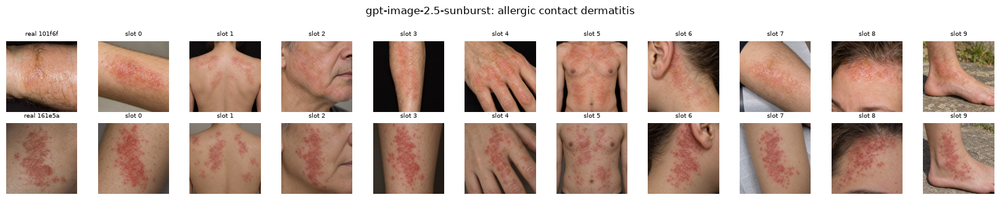

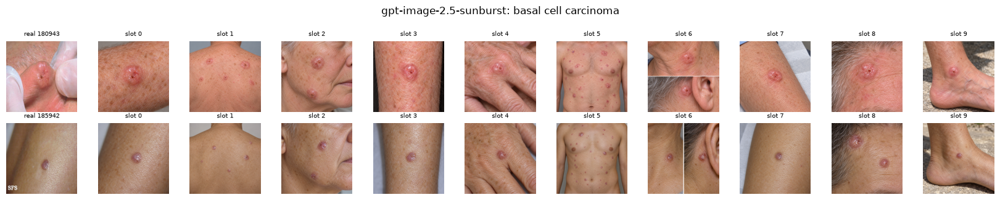

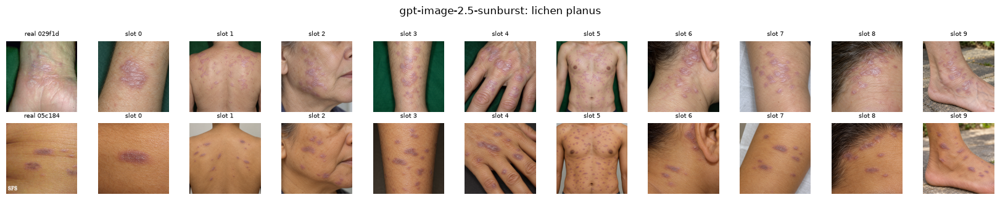

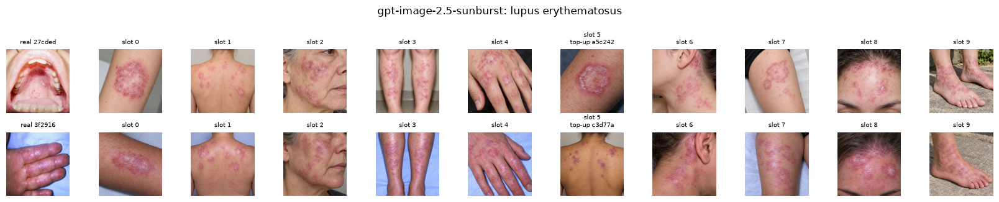

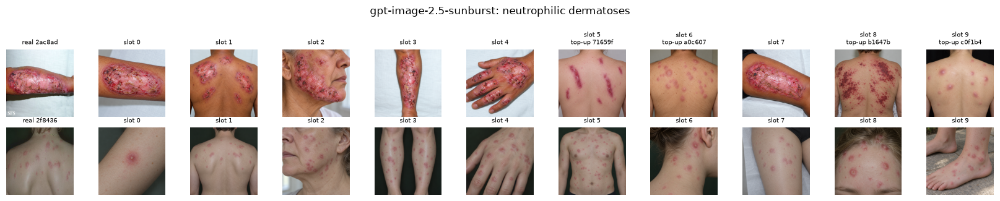

...

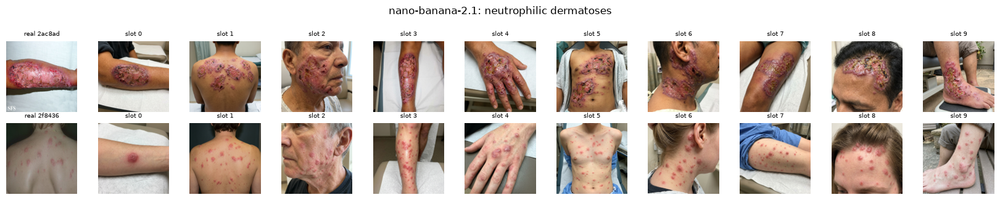

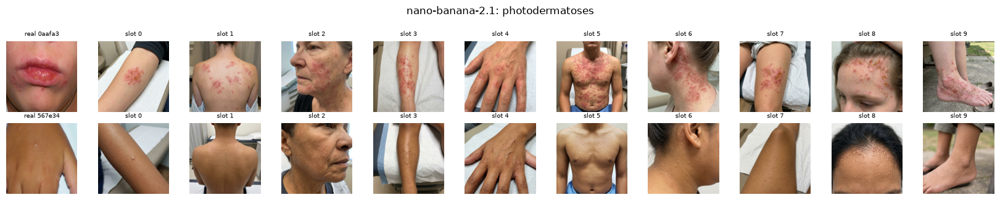

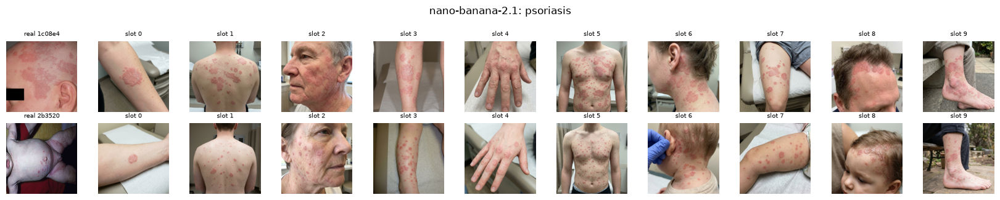

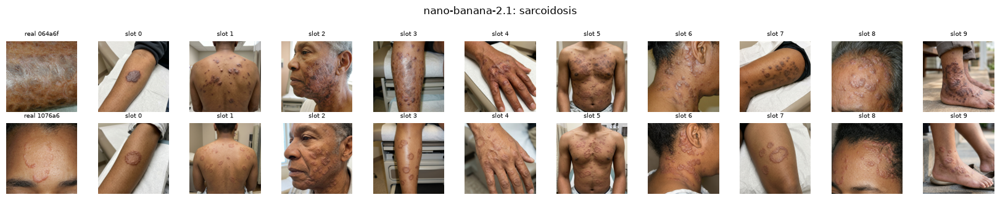

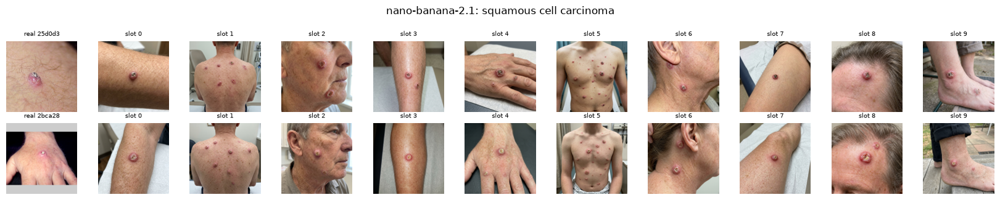

In [4]:
reals = pd.read_csv(PILOTS["gpt-image-2.5-sunburst"] + "/reals.csv")   # the same split for both models
labels = sorted(reals.label.unique())
for name, d in PILOTS.items():
    syn = pd.read_csv(d + "/synthetic.csv")
    for label in labels:
        refs = reals[reals.label == label].sort_values("md5hash").md5hash.head(N_REFS).tolist()
        fig, axes = plt.subplots(len(refs), 11, figsize=(11 * 1.5, len(refs) * 1.6))
        for r, md5 in enumerate(refs):
            ax = axes[r][0]
            ax.imshow(Image.open(f"{REAL_DIR}/{md5}.jpg").convert("RGB").resize((THUMB, THUMB))); ax.set_title(f"real {md5[:6]}", fontsize=7)
            rows = syn[syn.md5hash == md5].set_index("slot")
            for slot in range(10):
                ax = axes[r][slot + 1]
                if slot in rows.index:
                    row = rows.loc[slot]
                    ax.imshow(Image.open(row.location).convert("RGB").resize((THUMB, THUMB)))
                    ax.set_title(f"slot {slot}" + (f"\ntop-up {row.source_md5[:6]}" if row.topup else ""), fontsize=7)
                else:
                    ax.set_title(f"slot {slot}: missing", fontsize=7)
        for ax in axes.ravel(): ax.axis("off")
        fig.suptitle(f"{name}: {label}", y=1.0); fig.tight_layout(); plt.show()